# 10: ADC, 64QAM, MI e GMI, PAM4 e inclinação da dispersão

O notebook 09 ficou com o 16QAM e a reprodução do VPI, inclusive o DSP cego. Aqui fica o que não entra nessa reprodução:

- ADC com quantização
- 64QAM
- MI e GMI
- PAM4 no IMDD
- Inclinação da dispersão na fibra

Tudo roda pelo simcopy, a partir dos exemplos em YAML. A célula abaixo prepara o canal DP-16QAM de `coerente_dp16qam.yaml` com o receptor cego, que a seção do ADC usa.

In [1]:
import dataclasses
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from simcopy.plotting import apply_style
apply_style()          # estilo das figuras: guia de figuras do TCC (src/simcopy/plotting.py)

import simcopy
from simcopy.config.io import load
from simcopy.config.simulation import SimulationConfig
from simcopy.core.units import dbm_to_w
from simcopy.kernels.mapping import constellation
from simcopy.pipelines.runner import run, with_value

examples = Path(simcopy.__file__).parents[2] / "examples"
dp_system, dp_simulation = load(examples / "coerente_dp16qam.yaml")
short = SimulationConfig.from_symbols(59.84e9, 16, 2 ** 13, root_seed=0)

def with_channel(system, dsp_fields=None, adc_fields=None, **channel_fields):
    """O mesmo sistema, com outros campos do canal, de rx.dsp e de rx.adc."""
    c = system.channels[0]
    rx = dataclasses.replace(c.rx, dsp=dataclasses.replace(c.rx.dsp, **(dsp_fields or {})),
                             adc=dataclasses.replace(c.rx.adc, **(adc_fields or {})))
    return dataclasses.replace(system, channels=(dataclasses.replace(c, rx=rx, **channel_fields),))

def power_sweep(system, simulation, powers):
    """Métricas do canal 0 para cada potência na entrada do receptor."""
    out = []
    for p in powers:
        s, _ = with_value(system, simulation, "channels[0].launch_power", dbm_to_w(p))
        out.append(run(s, simulation).metrics[0])
    return out

blind = dict(mode="blind", phase_window=81)

## ADC: quantos bits

O ADC quantiza a parte real e a imaginária de cada polarização em $2^b$ níveis, com fundo de escala de 4 vezes o valor rms. Sem ceifamento, o ruído de quantização fica $6{,}02\,b + 4{,}77 - 20\log_{10}4$ dB abaixo do sinal. Variamos o número de bits com −20 dBm no receptor.

 bits | SNR medida [dB] | SQNR da fórmula [dB] | 1/SNR medida menos 1/SNR com 12 bits, em dB
    3 |           11.43 |                10.79 | 12.58
    4 |           14.98 |                16.81 | 18.20
    5 |           16.72 |                22.83 | 23.37
    6 |           17.44 |                28.85 | 28.67
    8 |           17.75 |                40.89 | 38.50
   12 |           17.78 |                64.97 | sem diferença


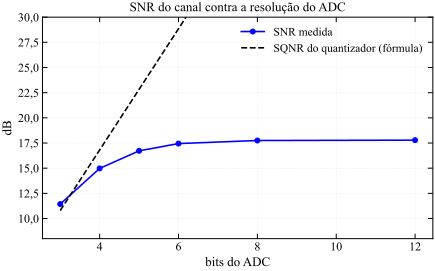

In [2]:
bit_list = (3, 4, 5, 6, 8, 12)
adc_snr = []
for bits_adc in bit_list:
    s = with_channel(dp_system, blind, adc_fields=dict(resolution_bits=bits_adc))
    adc_snr.append(run(s, short).metrics[0].snr_db)

sqnr = 6.02 * np.array(bit_list) + 4.77 - 20 * np.log10(4.0)
print(" bits | SNR medida [dB] | SQNR da fórmula [dB] | 1/SNR medida menos 1/SNR com 12 bits, em dB")
for b, measured, formula in zip(bit_list, adc_snr, sqnr):
    extra = 10 ** (-measured / 10) - 10 ** (-adc_snr[-1] / 10)
    print(f"{b:5d} | {measured:15.2f} | {formula:20.2f} | " + (f"{-10 * np.log10(extra):.2f}" if extra > 1e-6 else "sem diferença"))

fig, ax = plt.subplots(1, 1, figsize=(7, 4))
ax.plot(bit_list, adc_snr, "o-", label="SNR medida")
ax.plot(bit_list, sqnr, "k--", label="SQNR do quantizador (fórmula)")
ax.set(xlabel="bits do ADC", ylabel="dB", title="SNR do canal contra a resolução do ADC", ylim=(8, 30))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

Com 12 e com 8 bits a SNR é a mesma (17,78 e 17,75 dB): o ruído de quantização fica muito abaixo do ruído do receptor. Com 6 bits a perda é de 0,3 dB, com 5 bits de 1,1 dB, com 4 bits de 2,8 dB e com 3 bits de 6,4 dB.

A última coluna é a relação entre o sinal e o ruído que o ADC acrescentou, tirada da diferença para os 12 bits. Com 5 e 6 bits ela bate com a fórmula do quantizador (23,4 e 28,7 dB medidos, 22,8 e 28,9 pela fórmula). Com 3 e 4 bits o ADC acrescenta menos ruído do que a fórmula diz (1,8 e 1,4 dB a menos). Com 8 bits a diferença para os 12 bits já é pequena demais para medir bem.

## 64QAM, MI e GMI

O 64QAM leva 6 bits por símbolo, com 8 níveis por eixo e o mesmo código de Gray do 16QAM. O exemplo `examples/coerente_dp64qam.yaml` tem um transmissor mais limpo que o do cenário do VPI, porque o 64QAM pede mais SNR.

A BER diz quantos bits chegaram errados. A MI e a GMI dizem quantos bits por símbolo um código corretor de erros conseguiria aproveitar: a MI com decodificação por símbolo, a GMI com decodificação bit a bit, que é o caso dos códigos usados em sistemas ópticos. Elas saem dos símbolos recebidos, supondo ruído gaussiano com a variância medida.

Para comparar os dois formatos no mesmo transmissor e no mesmo receptor, trocamos só a modulação do exemplo.

canal 0: BER contada = 3.677e-04 (72/195816) | EVM = 6.89 % (SNR = 23.24 dB) | Q = 3.323 | BER por Q = 4.461e-04 | potencia recebida = -20.00 dBm | instante = 5 amostras | simbolos 33 a 16350 | MI = 5.992, GMI = 5.992 bits/simbolo | SER = 2.206e-03 | por polarizacao: SNR = 23.25, 23.23 dB, BER = 3.881e-04, 3.473e-04


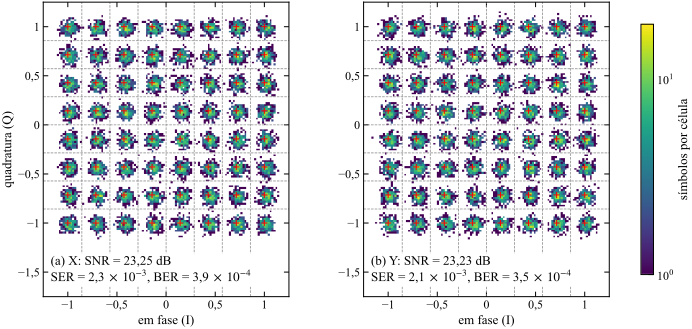

 P [dBm] | 16QAM: SNR  GMI   BER      | 64QAM: SNR  GMI   BER
     -32 |      12.32 3.632 2.48e-02 |      12.32 3.875 1.09e-01
     -30 |      14.29 3.879 7.97e-03 |      14.28 4.466 7.54e-02
     -28 |      16.23 3.979 1.40e-03 |      16.21 5.015 4.66e-02
     -26 |      18.15 3.999 4.61e-05 |      18.09 5.480 2.35e-02
     -24 |      20.01 4.000 0.00e+00 |      19.92 5.795 9.01e-03
     -22 |      21.81 4.000 0.00e+00 |      21.66 5.948 2.19e-03
     -20 |      23.49 4.000 0.00e+00 |      23.26 5.993 3.18e-04
     -18 |      25.04 4.000 0.00e+00 |      24.70 6.000 1.03e-05
     -16 |      26.40 4.000 0.00e+00 |      25.94 6.000 0.00e+00


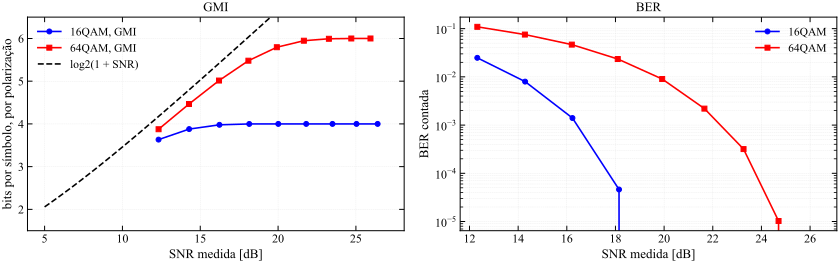

In [3]:
from simcopy.config.system import QAM16
from simcopy.plotting import plot_constellation

qam64_system, qam64_simulation = load(examples / "coerente_dp64qam.yaml")
qam64 = run(qam64_system, qam64_simulation)
print(qam64.summary())
plot_constellation(qam64)
plt.show()

# o mesmo transmissor e o mesmo receptor, com 16QAM
qam16_system = dataclasses.replace(
    qam64_system, channels=(dataclasses.replace(qam64_system.channels[0], modulation=QAM16),))
short32 = SimulationConfig.from_symbols(32e9, 16, 2 ** 13, root_seed=1)
rate_powers = np.arange(-32.0, -15.0, 2.0)
sweep16 = power_sweep(qam16_system, short32, rate_powers)
sweep64 = power_sweep(qam64_system, short32, rate_powers)

print(" P [dBm] | 16QAM: SNR  GMI   BER      | 64QAM: SNR  GMI   BER")
for p, a, b in zip(rate_powers, sweep16, sweep64):
    print(f"{p:8.0f} | {a.snr_db:10.2f} {a.gmi:5.3f} {a.ber_counted:.2e} | {b.snr_db:10.2f} {b.gmi:5.3f} {b.ber_counted:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
snr16 = np.array([m.snr_db for m in sweep16])
snr64 = np.array([m.snr_db for m in sweep64])
ax[0].plot(snr16, [m.gmi for m in sweep16], "o-", label="16QAM, GMI")
ax[0].plot(snr64, [m.gmi for m in sweep64], "s-", label="64QAM, GMI")
grid_snr = np.linspace(5, 27, 100)
ax[0].plot(grid_snr, np.log2(1 + 10 ** (grid_snr / 10)), "k--", label="log2(1 + SNR)")
ax[0].set(xlabel="SNR medida [dB]", ylabel="bits por símbolo, por polarização", title="GMI", ylim=(1.5, 6.5))
ax[1].semilogy(snr16, [m.ber_counted for m in sweep16], "o-", label="16QAM")
ax[1].semilogy(snr64, [m.ber_counted for m in sweep64], "s-", label="64QAM")
ax[1].set(xlabel="SNR medida [dB]", ylabel="BER contada", title="BER")
for a in ax:
    a.grid(True, which="both", alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

No exemplo, o 64QAM a −20 dBm tem SNR de 23,24 dB, 72 erros em 195816 bits e GMI de 5,99 bits por símbolo.

No mesmo transmissor e receptor, a SNR dos dois formatos é quase a mesma em cada potência, e o que muda é o quanto cada um aproveita dela. A 12,3 dB o 16QAM carrega 3,63 bits e o 64QAM 3,88. A 18,1 dB o 16QAM já chegou ao seu teto de 4 bits e o 64QAM carrega 5,48. A GMI do 64QAM é sempre a maior, embora a BER dele seja muito pior (2,4e-2 contra 4,6e-5 a 18,1 dB): mais erros por símbolo, e ainda assim mais informação, que o código corretor recupera. As duas curvas de GMI ficam abaixo de log2(1 + SNR), o limite de qualquer formato.

## PAM4 no IMDD

No IMDD, o PAM4 leva 2 bits por símbolo em quatro níveis de potência. Os bits escolhem o nível pelo código de Gray: 00, 01, 11, 10, do mais baixo ao mais alto. O exemplo `examples/imdd_pam4_mzm.yaml` usa laser CW e MZM, 10 GBd e 10 km de fibra.

A medida trata cada um dos três olhos como o olho do OOK: um limiar ótimo e um fator Q por olho. A BER pelos fatores Q é

$$\mathrm{BER} = \frac{1}{2}\cdot\frac{1}{4}\sum_{i=1}^{3}\mathrm{erfc}\!\left(\frac{Q_i}{\sqrt2}\right)$$

que com dois níveis volta à fórmula do notebook 07.

canal 0: Q = 44.559 (32.98 dB) | BER por Q = 0.000e+00 | erros contados = 0/8140 | potencia recebida = 4.99 dBm | instante = 16 amostras | simbolos 13 a 4082 | Q por olho = 70.84, 69.08, 44.56 | SER = 0.000e+00


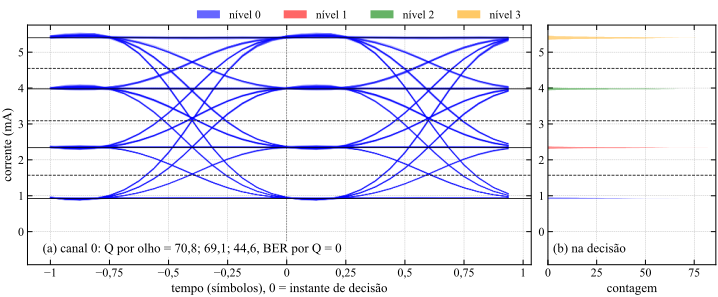

 P [dBm] | Q dos três olhos    | BER por Q | BER contada


     -18 | 2.06 / 2.36 / 2.05  | 1.229e-02 | 1.171e-02 (383 erros)


     -19 | 1.64 / 1.88 / 1.63  | 3.277e-02 | 3.170e-02 (1037 erros)


     -20 | 1.31 / 1.50 / 1.30  | 6.452e-02 | 6.394e-02 (2092 erros)


     -21 | 1.05 / 1.19 / 1.04  | 1.035e-01 | 1.036e-01 (3389 erros)


In [4]:
from simcopy.plotting import plot_eye

pam_system, pam_simulation = load(examples / "imdd_pam4_mzm.yaml")
pam = run(pam_system, pam_simulation)
print(pam.summary())
plot_eye(pam)
plt.show()

# com pouca potência há erros para contar
pam_long = SimulationConfig.from_symbols(10e9, 16, 2 ** 14, root_seed=1)
print(" P [dBm] | Q dos três olhos    | BER por Q | BER contada")
for p in (-18.0, -19.0, -20.0, -21.0):
    s, _ = with_value(pam_system, pam_long, "channels[0].launch_power", dbm_to_w(p))
    m = run(s, pam_long).metrics[0]
    print(f"{p:8.0f} | " + " / ".join(f"{q:.2f}" for q in m.eye_q) + f"  | {m.ber_q:.3e} | {m.ber_counted:.3e} ({m.errors} erros)")

Com 5 dBm no receptor os três olhos estão abertos, com Q de 71, 69 e 44, e não há erros. Os quatro níveis de corrente não são igualmente espaçados com a excursão inteira do MZM, e por isso o exemplo usa metade da excursão: os níveis ficam em 0,9, 2,3, 4,0 e 5,4 mA.

Baixando a potência, a BER contada segue a estimada pelos fatores Q em toda a faixa: 1,17e-2 contada contra 1,23e-2 a −18 dBm, 1,036e-1 contra 1,035e-1 a −21 dBm. O olho do meio tem Q um pouco maior que os outros dois, então são os olhos de fora que limitam.

## Inclinação da dispersão

Até aqui a fibra só tinha $\beta_2$. A inclinação da dispersão $S = dD/d\lambda$ dá o termo seguinte, $\beta_3$ (Agrawal, Eq. 2.3.13). No arquivo do VPI, $S$ = 0,08 ps/(nm²·km).

Para ver só o efeito de $\beta_3$, propagamos um pulso gaussiano de 1 ps com $\beta_2 = 0$ e sem efeito Kerr. O Agrawal dá o alargamento rms (Eq. 2.4.22): $\sigma/\sigma_0 = \sqrt{1 + (\beta_3 L/(4\sqrt2\,\sigma_0^3))^2}$.

beta3 = 0.163 ps³/km
 L [km] | sigma/sigma0 medido | Eq. 2.4.22 | centro do pulso [ps]
      5 |            1.079664 |   1.079664 | +0.204
     20 |            1.910704 |   1.910704 | +0.814
     50 |            4.191352 |   4.191352 | +2.035


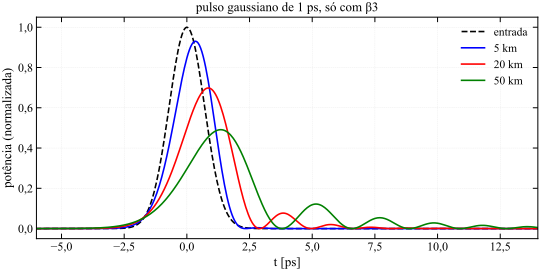

In [5]:
from simcopy.core.units import C_LIGHT, beta3_from_dispersion
from simcopy.kernels.ssfm import FiberKernelParams, propagate

wavelength = C_LIGHT / 193.7e12
beta3 = beta3_from_dispersion(16e-6, 0.08e3, wavelength)
print(f"beta3 = {beta3 * 1e39:.3f} ps³/km")

n, dt, T0 = 2 ** 14, 0.05e-12, 1.0e-12
t = (np.arange(n) - n // 2) * dt
omega = 2 * np.pi * np.fft.fftfreq(n, dt)
pulse = np.exp(-t ** 2 / (2 * T0 ** 2)).astype(complex)[None, :]
sigma0 = T0 / np.sqrt(2)

def rms_width(field):
    power = np.abs(field) ** 2
    center = np.sum(t * power) / np.sum(power)
    return np.sqrt(np.sum((t - center) ** 2 * power) / np.sum(power)), center

fig, ax = plt.subplots(1, 1, figsize=(9, 4))
ax.plot(t * 1e12, np.abs(pulse[0]) ** 2, "k--", label="entrada")
print(" L [km] | sigma/sigma0 medido | Eq. 2.4.22 | centro do pulso [ps]")
for length in (5e3, 20e3, 50e3):
    out = propagate(pulse, omega, FiberKernelParams(length=length, beta2=0.0, gamma=0.0, alpha_np=0.0, beta3=beta3))
    width, center = rms_width(out[0])
    closed = np.sqrt(1 + (beta3 * length / (4 * np.sqrt(2) * sigma0 ** 3)) ** 2)
    print(f"{length / 1e3:7.0f} | {width / sigma0:19.6f} | {closed:10.6f} | {center * 1e12:+.3f}")
    ax.plot(t * 1e12, np.abs(out[0]) ** 2, label=f"{length / 1e3:.0f} km")
ax.set(xlabel="t [ps]", ylabel="potência (normalizada)", xlim=(-6, 14), title="pulso gaussiano de 1 ps, só com β3")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

O alargamento medido é igual ao da Eq. 2.4.22 nas seis casas, nas três distâncias. O pulso não alarga de forma simétrica, como com $\beta_2$: ele ganha uma cauda oscilante de um lado só, e o centro se atrasa (+0,20 ps em 5 km, +2,0 ps em 50 km). Com $\beta_3 > 0$ todas as componentes de frequência chegam depois da portadora, por isso o atraso é sempre positivo.

No cenário de 4 canais do VPI o efeito é pequeno: ligar a inclinação mudou a SNR em 0,02 dB.

## O que falta

- Código corretor de erros
- 32QAM